In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/Sample - Superstore.csv",
                encoding="cp1252"
                )
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.shape

(9994, 21)

In [4]:
df.columns


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
df.duplicated().sum()


np.int64(0)

In [7]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [8]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object

In [9]:
# Convert identifier and descriptive text columns to string dtype
string_columns = [
    "Order ID",
    "Customer ID",
    "Customer Name",
    "Product ID",
    "Product Name"
]

df[string_columns] = df[string_columns].astype("string")

In [10]:
# Convert repeated-label columns to category dtype
category_columns = [
    "Ship Mode",
    "Segment",
    "Country",
    "Region",
    "State",
    "City",
    "Category",
    "Sub-Category"
]

df[category_columns] = df[category_columns].astype("category")

In [11]:
df["Region"].value_counts()

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

In [12]:
df["Segment"].value_counts()

Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

In [13]:
remaining_columns = [
    "Ship Mode",
    "Country",
    "State",
    "City",
    "Category",
    "Sub-Category"
]

for col in remaining_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Ship Mode ---
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

--- Country ---
Country
United States    9994
Name: count, dtype: int64

--- State ---
State
California              2001
New York                1128
Texas                    985
Pennsylvania             587
Washington               506
Illinois                 492
Ohio                     469
Florida                  383
Michigan                 255
North Carolina           249
Virginia                 224
Arizona                  224
Georgia                  184
Tennessee                183
Colorado                 182
Indiana                  149
Kentucky                 139
Massachusetts            135
New Jersey               130
Oregon                   124
Wisconsin                110
Maryland                 105
Delaware                  96
Minnesota                 89
Connecticut               82
Oklahoma                  66
Misso

In [14]:
df[["Sales", "Profit", "Discount", "Quantity"]].describe()

,Sales,Profit,Discount,Quantity
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,0.156203,3.789574
std,623.245101,234.260108,0.206452,2.225110
min,0.444000,-6599.978000,0.000000,1.000000
25%,17.280000,1.728750,0.000000,2.000000
50%,54.490000,8.666500,0.200000,3.000000
75%,209.940000,29.364000,0.200000,5.000000
max,22638.480000,8399.976000,0.800000,14.000000


In [15]:
# 5. Executive Financial Overview

## 5.1 Key Performance Indicators (KPIs)

# In this section, we will calculate the key financial and operational metrics
# to understand the overall performance of the business.


In [16]:
total_sales = df["Sales"].sum()
total_sales

np.float64(2297200.8603)

In [17]:
total_profit = df["Profit"].sum()
total_profit

np.float64(286397.0217)

In [18]:
total_orders = df["Order ID"].nunique()
total_orders

5009

In [19]:
total_quantity = df["Quantity"].sum()
total_quantity

np.int64(37873)

In [20]:
profit_margin = (total_profit / total_sales) * 100
profit_margin

np.float64(12.467217240315605)

In [21]:
average_order_value = total_sales / total_orders
average_order_value

np.float64(458.6146656618087)

In [22]:
df["Processing Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

average_shipping_duration = df["Processing Days"].mean()
average_shipping_duration

np.float64(3.958174904942966)

In [23]:
## create a column for order year

df["Year"] = df["Order Date"].dt.year

In [24]:
## create a column for order month

df["Month"] = df["Order Date"].dt.month

In [25]:
## create a column for order month name

df["Month Name"] = df["Order Date"].dt.month_name()



In [26]:
monthly_sales = (
    df.groupby(["Year", "Month", "Month Name"], observed=True)["Sales"]
    .sum()
    .reset_index()
)

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

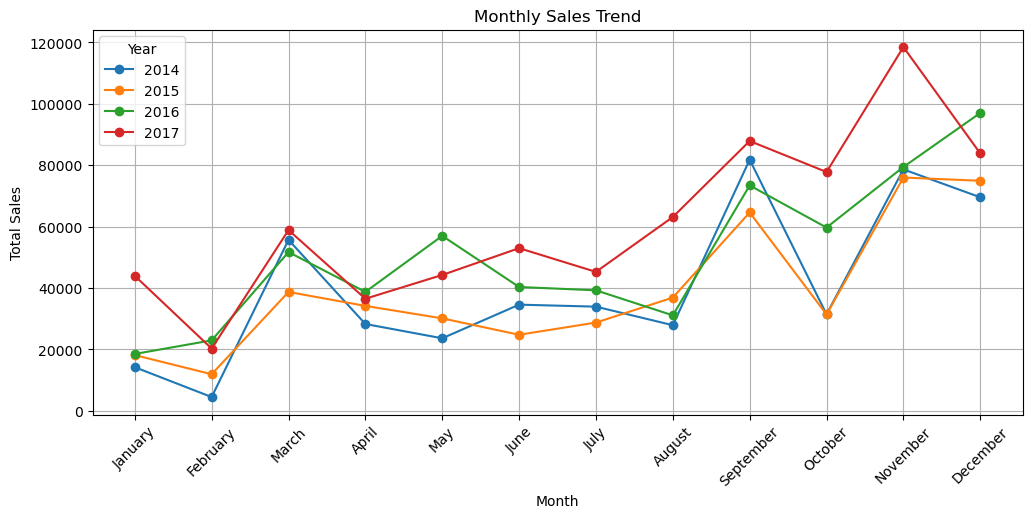

In [27]:
## Monthly sales trend

plt.figure(figsize=(12, 5))

for year in monthly_sales["Year"].unique():
    year_data = monthly_sales[monthly_sales["Year"] == year]

    plt.plot(
        year_data["Month"],
        year_data["Sales"],
        marker="o",
        label=year
    )

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13), month_order, rotation = 45)
plt.legend(title="Year")
plt.grid(True)
plt.show()

In [28]:
yearly_sales = (df.groupby(["Year"])["Sales"].sum().reset_index()
)

yearly_sales

,Year,Sales
0,2014,484247.4981
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552


In [29]:
monthly_profit = (
    df.groupby(["Year", "Month", "Month Name"], observed=True)["Profit"]
    .sum()
    .reset_index()
)

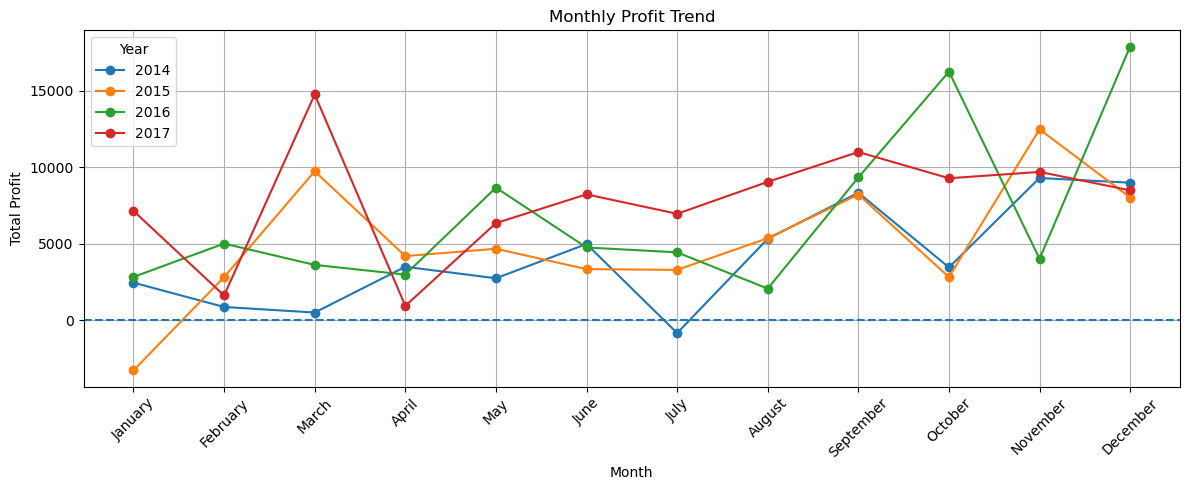

In [30]:
plt.figure(figsize=(12, 5))

for year in monthly_profit["Year"].unique():
    year_data = monthly_profit[monthly_profit["Year"] == year]
    year_data = year_data.sort_values("Month")

    plt.plot(
        year_data["Month"],
        year_data["Profit"],
        marker="o",
        label=year
    )

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")

plt.xticks(
    range(1, 13),
    month_order,
    rotation=45
)

plt.legend(title="Year")
plt.grid(True)
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()

In [31]:
yearly_profit = (df.groupby(["Year"])["Profit"].sum().reset_index()
)

yearly_profit

,Year,Profit
0,2014,49543.9741
1,2015,61618.6037
2,2016,81795.1743
3,2017,93439.2696


In [32]:
yearly_performance = pd.merge(
    yearly_sales,
    yearly_profit,
    on="Year"
)

yearly_performance["Profit Margin"] = (
    yearly_performance["Profit"] /
    yearly_performance["Sales"]
) * 100

yearly_performance

,Year,Sales,Profit,Profit Margin
0,2014,484247.4981,49543.9741,10.231126
1,2015,470532.5090,61618.6037,13.095504
2,2016,609205.5980,81795.1743,13.426530
3,2017,733215.2552,93439.2696,12.743771


In [33]:
yearly_performance["Sales Growth %"] = (
    yearly_performance["Sales"].pct_change() * 100
)

yearly_performance["Profit Growth %"] = (
    yearly_performance["Profit"].pct_change() * 100
)

yearly_performance

,Year,Sales,Profit,Profit Margin,Sales Growth %,Profit Growth %
0,2014,484247.4981,49543.9741,10.231126,NaN,NaN
1,2015,470532.5090,61618.6037,13.095504,-2.832227,24.371540
2,2016,609205.5980,81795.1743,13.426530,29.471521,32.744284
3,2017,733215.2552,93439.2696,12.743771,20.355962,14.235675


In [34]:
monthly_processing = (
    df.groupby(
        ["Year", "Month", "Month Name"],
        observed=True
    )["Processing Days"]
    .mean()
    .reset_index()
)

monthly_processing.sort_values(
    "Processing Days",
    ascending=False
)

,Year,Month,Month Name,Processing Days
12,2015,1,January,4.741379
27,2016,4,April,4.458824
37,2017,2,February,4.373832
15,2015,4,April,4.337500
31,2016,8,August,4.329545
20,2015,9,September,4.290102
10,2014,11,November,4.261006
33,2016,10,October,4.188776
5,2014,6,June,4.177778
1,2014,2,February,4.173913


In [35]:
## Sales of category

category_sales = (
    df.groupby("Category", observed=True)["Sales"]
    .sum()
    .reset_index()
)

category_sales

,Category,Sales
0,Furniture,741999.7953
1,Office Supplies,719047.0320
2,Technology,836154.0330


In [36]:
## Category wise profit

category_profit = (
    df.groupby("Category", observed=True)["Profit"]
    .sum()
    .reset_index()
)

category_profit

,Category,Profit
0,Furniture,18451.2728
1,Office Supplies,122490.8008
2,Technology,145454.9481


In [37]:
## Profit Margin

category_performance = pd.merge(
    category_sales,
    category_profit,
    on="Category"
)

category_performance["Profit Margin"] = (
    category_performance["Profit"] /
    category_performance["Sales"]
) * 100

category_performance

,Category,Sales,Profit,Profit Margin
0,Furniture,741999.7953,18451.2728,2.486695
1,Office Supplies,719047.0320,122490.8008,17.035158
2,Technology,836154.0330,145454.9481,17.395712


In [38]:
## Profit by Sub-Category

subcategory_profit = (
    df.groupby("Sub-Category", observed=True)["Profit"]
    .sum()
    .reset_index()
)

subcategory_profit

,Sub-Category,Profit
0,Accessories,41936.6357
1,Appliances,18138.0054
2,Art,6527.7870
3,Binders,30221.7633
4,Bookcases,-3472.5560
5,Chairs,26590.1663
6,Copiers,55617.8249
7,Envelopes,6964.1767
8,Fasteners,949.5182
9,Furnishings,13059.1436


In [39]:
## Total sales by Sub-Category

subcategory_sales = (
    df.groupby("Sub-Category", observed=True)["Sales"]
    .sum()
    .reset_index()
)

subcategory_sales

,Sub-Category,Sales
0,Accessories,167380.3180
1,Appliances,107532.1610
2,Art,27118.7920
3,Binders,203412.7330
4,Bookcases,114879.9963
5,Chairs,328449.1030
6,Copiers,149528.0300
7,Envelopes,16476.4020
8,Fasteners,3024.2800
9,Furnishings,91705.1640


In [40]:
## Profit Margins by sub-category

subcategory_performance = pd.merge(
    subcategory_sales,
    subcategory_profit,
    on="Sub-Category"
)

subcategory_performance["Profit Margin"] = (
    subcategory_performance["Profit"] /
    subcategory_performance["Sales"]
) * 100

subcategory_performance

,Sub-Category,Sales,Profit,Profit Margin
0,Accessories,167380.3180,41936.6357,25.054700
1,Appliances,107532.1610,18138.0054,16.867517
2,Art,27118.7920,6527.7870,24.071083
3,Binders,203412.7330,30221.7633,14.857361
4,Bookcases,114879.9963,-3472.5560,-3.022768
5,Chairs,328449.1030,26590.1663,8.095673
6,Copiers,149528.0300,55617.8249,37.195585
7,Envelopes,16476.4020,6964.1767,42.267582
8,Fasteners,3024.2800,949.5182,31.396504
9,Furnishings,91705.1640,13059.1436,14.240358


In [41]:
## Most profitable and loss making product

top_profit_subcategories = subcategory_performance.nlargest(
    5, "Profit"
)

bottom_profit_subcategories = subcategory_performance.nsmallest(
    5, "Profit"
)

top_profit_subcategories



,Sub-Category,Sales,Profit,Profit Margin
6,Copiers,149528.030,55617.8249,37.195585
13,Phones,330007.054,44515.7306,13.489327
0,Accessories,167380.318,41936.6357,25.054700
12,Paper,78479.206,34053.5693,43.391837
3,Binders,203412.733,30221.7633,14.857361


In [42]:
bottom_profit_subcategories

,Sub-Category,Sales,Profit,Profit Margin
16,Tables,206965.5320,-17725.4811,-8.564460
4,Bookcases,114879.9963,-3472.5560,-3.022768
15,Supplies,46673.5380,-1189.0995,-2.547695
8,Fasteners,3024.2800,949.5182,31.396504
11,Machines,189238.6310,3384.7569,1.788618


In [43]:
avg_discount = df[df["Sub-Category"] == "Tables"]["Discount"].mean()

avg_discount

np.float64(0.26128526645768024)

In [44]:
subcategory_discount = (
    df.groupby("Sub-Category", observed=True)["Discount"]
    .mean()
    .reset_index()
)

subcategory_discount

,Sub-Category,Discount
0,Accessories,0.078452
1,Appliances,0.166524
2,Art,0.074874
3,Binders,0.372292
4,Bookcases,0.211140
5,Chairs,0.170178
6,Copiers,0.161765
7,Envelopes,0.080315
8,Fasteners,0.082028
9,Furnishings,0.138349


In [45]:
## Profit of individual product

product_profit = (
    df.groupby(["Product ID", "Product Name"], observed=True)["Profit"]
    .sum()
    .reset_index()
)

product_profit

,Product ID,Product Name,Profit
0,FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",-117.8820
1,FUR-BO-10000330,"Sauder Camden County Barrister Bookcase, Plank...",24.1960
2,FUR-BO-10000362,Sauder Inglewood Library Bookcases,311.1836
3,FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,-133.1092
4,FUR-BO-10000711,"Hon Metal Bookcases, Gray",229.9752
...,...,...,...
1889,TEC-PH-10004912,Cisco SPA112 2 Port Phone Adapter,87.3705
1890,TEC-PH-10004922,RCA Visys Integrated PBX 8-Line Router,130.6305
1891,TEC-PH-10004924,"SKILCRAFT Telephone Shoulder Rest, 2"" x 6.5"" x...",13.0064
1892,TEC-PH-10004959,Classic Ivory Antique Telephone ZL1810,40.1960


In [46]:
# Top 10 profitable product

top_10_products = product_profit.nlargest(10, "Profit")

top_10_products

,Product ID,Product Name,Profit
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,25199.9280
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,7753.0390
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,6983.8836
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,4570.9347
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,4094.9766
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,3772.9461
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,3696.2820
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,3345.2823
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,3343.5360


In [47]:
# Bottom 10 profitable product

bottom_10_products = product_profit.nsmallest(10, "Profit")

bottom_10_products

,Product ID,Product Name,Profit
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,-8879.9704
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,-3839.9904
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-2876.1156
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,-1934.3976
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,-1878.1662
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,-1811.0784
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,-1299.1836
346,FUR-TA-10001950,Balt Solid Wood Round Tables,-1201.0581
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,-1148.4375


In [48]:
discount_distribution = df["Discount"].value_counts().sort_index()
discount_distribution

Discount
0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     227
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300
Name: count, dtype: int64

In [49]:
## Checking whether the discounts affect the sales

discount_sales = (
    df.groupby("Discount")["Sales"]
    .sum()
    .reset_index()
)

discount_sales

,Discount,Sales
0,0.00,1.087908e+06
1,0.10,5.436935e+04
2,0.15,2.755852e+04
3,0.20,7.645944e+05
4,0.30,1.032267e+05
5,0.32,1.449346e+04
6,0.40,1.164178e+05
7,0.45,5.484974e+03
8,0.50,5.891854e+04
9,0.60,6.644700e+03


In [50]:
## Checking whether discount affect the profit

discount_profit = (
    df.groupby("Discount")["Profit"]
    .sum()
    .reset_index()
)

discount_profit

,Discount,Profit
0,0.00,320987.6032
1,0.10,9029.1770
2,0.15,1418.9915
3,0.20,90337.3060
4,0.30,-10369.2774
5,0.32,-2391.1377
6,0.40,-23057.0504
7,0.45,-2493.1111
8,0.50,-20506.4281
9,0.60,-5944.6552


In [51]:
## Checking if we are able to sell more quantity by increasing discount

discount_quantity = (
    df.groupby(["Discount"])["Quantity"]
    .sum()
    .reset_index()
)

discount_quantity

,Discount,Quantity
0,0.00,18267
1,0.10,373
2,0.15,198
3,0.20,13660
4,0.30,849
5,0.32,105
6,0.40,786
7,0.45,45
8,0.50,241
9,0.60,501


In [54]:
## Loss contribution by discount level

loss_contribution = df[df["Profit"]<0].groupby(["Discount"])["Profit"].sum().reset_index()

loss_contribution

,Discount,Profit
0,0.10,-29.2744
1,0.15,-328.7030
2,0.20,-17258.0654
3,0.30,-10777.6879
4,0.32,-2391.1377
5,0.40,-25787.8268
6,0.45,-2493.1111
7,0.50,-20506.4281
8,0.60,-5944.6552
9,0.70,-40075.3569


In [54]:
## Region wise sales

region_sales = (
    df.groupby("Region", observed=True)["Sales"]
    .sum()
    .reset_index()
)

region_sales

,Region,Sales
0,Central,501239.8908
1,East,678781.2400
2,South,391721.9050
3,West,725457.8245


In [55]:
## Region wise profit

region_profit = (
    df.groupby("Region", observed=True)["Profit"]
    .sum()
    .reset_index()
)

region_profit

,Region,Profit
0,Central,39706.3625
1,East,91522.7800
2,South,46749.4303
3,West,108418.4489


In [57]:
## Region wise profit margin

region_performance = pd.merge(
    region_sales,
    region_profit,
    on="Region"
)

region_performance["Profit Margin"] = (
    region_performance["Profit"] /
    region_performance["Sales"]
) * 100

region_performance

,Region,Sales,Profit,Profit Margin
0,Central,501239.8908,39706.3625,7.921629
1,East,678781.2400,91522.7800,13.483399
2,South,391721.9050,46749.4303,11.934342
3,West,725457.8245,108418.4489,14.944831


In [59]:
## state wise profit

state_profit = (
    df.groupby("State", observed=True)["Profit"]
    .sum()
    .reset_index()
)


In [60]:
## Top 5 profitable state

top_states = state_profit.nlargest(5, "Profit")
top_states

,State,Profit
3,California,76381.3871
30,New York,74038.5486
45,Washington,33402.6517
20,Michigan,24463.1876
44,Virginia,18597.9504


In [61]:
## Bottom 5 profitable state

bottom_states = state_profit.nsmallest(5, "Profit")
bottom_states

,State,Profit
41,Texas,-25729.3563
33,Ohio,-16971.3766
36,Pennsylvania,-15559.9603
11,Illinois,-12607.8870
31,North Carolina,-7490.9122


In [62]:
df.to_csv("../data/Superstore_Cleaned.csv", index=False)